<a href="https://colab.research.google.com/github/pradeep1992official/UrbanPulse/blob/main/URBAN_PULSE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/1.Learning & Training/guvi/Mini_Project/nyc_311_cleaned.csv")

print("Total rows:", len(df))
df.head()

Total rows: 100000


,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_zip,incident_address,street_name,cross_street_1,...,bridge_highway_direction,bridge_highway_segment,road_ramp,due_date,resolution_hours,is_closed,created_year,created_month,created_weekday,created_hour
0,70851698,2026-10-23 02:46:57,DOT,Department of Transportation,Street Condition,Pothole,10462.0,NEWBOLD AVENUE,NEWBOLD AVENUE,HAVEMEYER AVENUE,...,NaN,NaN,NaN,NaN,NaN,False,2026,10,Friday,2
1,70848912,2026-10-23 01:51:07,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Defective,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,False,2026,10,Friday,1
2,70850110,2026-10-23 01:50:50,NYPD,New York City Police Department,Noise - Street/Sidewalk,Loud Music/Party,10033.0,547 WEST 186 STREET,WEST 186 STREET,AUDUBON AVENUE,...,NaN,NaN,NaN,NaN,NaN,False,2026,10,Friday,1
3,70850735,2026-10-23 01:50:25,NYPD,New York City Police Department,Illegal Parking,Posted Parking Sign Violation,11215.0,180 PROSPECT WEST,PROSPECT WEST,13 STREET,...,NaN,NaN,NaN,NaN,NaN,False,2026,10,Friday,1
4,70849986,2026-10-23 01:50:21,NYPD,New York City Police Department,Illegal Parking,Blocked Crosswalk,11357.0,24-01 146 STREET,146 STREET,24 AVENUE,...,NaN,NaN,NaN,NaN,NaN,False,2026,10,Friday,1


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check the dataset is already loaded
print("Total rows:", len(df))

for col in df.columns:
    print(col, ":", "Available" if col in df.columns else "Missing")

Total rows: 100000
unique_key : Available
created_date : Available
agency : Available
agency_name : Available
complaint_type : Available
descriptor : Available
incident_zip : Available
incident_address : Available
street_name : Available
cross_street_1 : Available
cross_street_2 : Available
address_type : Available
city : Available
facility_type : Available
status : Available
resolution_description : Available
resolution_action_updated_date : Available
community_board : Available
police_precinct : Available
borough : Available
open_data_channel_type : Available
park_facility_name : Available
park_borough : Available
descriptor_2 : Available
location_type : Available
x_coordinate_state_plane : Available
y_coordinate_state_plane : Available
latitude : Available
longitude : Available
location : Available
intersection_street_1 : Available
intersection_street_2 : Available
landmark : Available
council_district : Available
bbl : Available
vehicle_type : Available
closed_date : Available
taxi

In [62]:
# Count complaints for each category
complaint_counts = df["complaint_type"].value_counts()

# Select the top 10
top10_complaints = complaint_counts.head(10)

print("TOP 10 COMPLAINT TYPES")
print(top10_complaints)

# Convert to a table
top10_table = top10_complaints.reset_index()
top10_table.columns = ["Complaint Type", "Total Requests"]

display(top10_table)


TOP 10 COMPLAINT TYPES
complaint_type
Illegal Parking            16398
HEAT/HOT WATER             11692
Noise - Residential         8971
Blocked Driveway            4905
UNSANITARY CONDITION        4249
Noise - Street/Sidewalk     3974
PLUMBING                    2186
Street Condition            2177
Noise                       2019
PAINT/PLASTER               2002
Name: count, dtype: int64


,Complaint Type,Total Requests
0,Illegal Parking,16398
1,HEAT/HOT WATER,11692
2,Noise - Residential,8971
3,Blocked Driveway,4905
4,UNSANITARY CONDITION,4249
5,Noise - Street/Sidewalk,3974
6,PLUMBING,2186
7,Street Condition,2177
8,Noise,2019
9,PAINT/PLASTER,2002


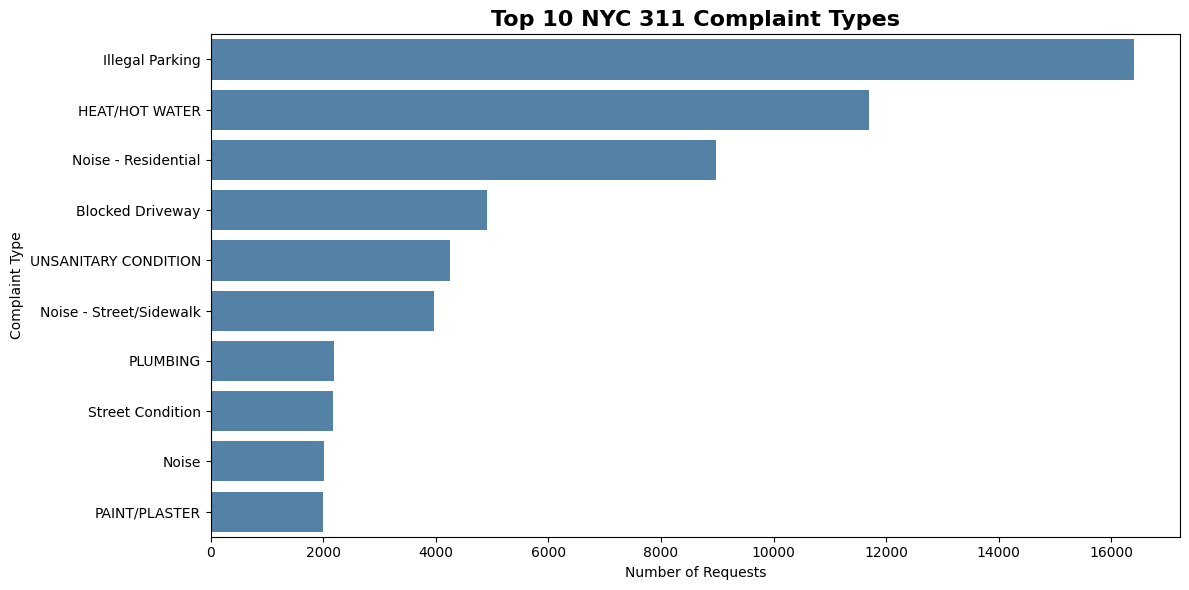

In [63]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top10_complaints.values,
    y=top10_complaints.index,
    color="steelblue"
)

plt.title(
    "Top 10 NYC 311 Complaint Types",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Requests")
plt.ylabel("Complaint Type")

plt.tight_layout()
plt.show()


In [64]:
top_category = top10_complaints.index[0]
top_count = top10_complaints.iloc[0]

percentage = (top_count / len(df)) * 100

print("Most common complaint:", top_category)
print("Number of requests:", top_count)
print("Percentage of all requests:", round(percentage, 2), "%")

Most common complaint: Illegal Parking
Number of requests: 16398
Percentage of all requests: 16.4 %


### Investigation 1 — Top 10 Complaint Categories

**Objective:** Identify the most frequently reported NYC 311 complaint categories.

**Method:** Used Pandas `value_counts()` to calculate category frequencies and displayed the top 10 in a horizontal bar chart.

**Finding:** The highest-ranked category was [category name], with [number] requests, representing [percentage]% of the analyzed dataset.

**Interpretation:** This category contributed the largest recorded complaint volume within the extracted sample. The finding can help describe service demand, but it does not establish the prevalence of problems across the entire city.

In [65]:
# Count records for each borough
borough_counts = df["borough"].value_counts(dropna=False)

print("BOROUGH-WISE REQUEST COUNTS")
print(borough_counts)

# Display as a table
borough_table = borough_counts.reset_index()
borough_table.columns = ["Borough", "Total Requests"]

display(borough_table)


BOROUGH-WISE REQUEST COUNTS
borough
BROOKLYN         32779
QUEENS           22303
MANHATTAN        21831
BRONX            19597
STATEN ISLAND     3382
Unspecified        108
Name: count, dtype: int64


,Borough,Total Requests
0,BROOKLYN,32779
1,QUEENS,22303
2,MANHATTAN,21831
3,BRONX,19597
4,STATEN ISLAND,3382
5,Unspecified,108


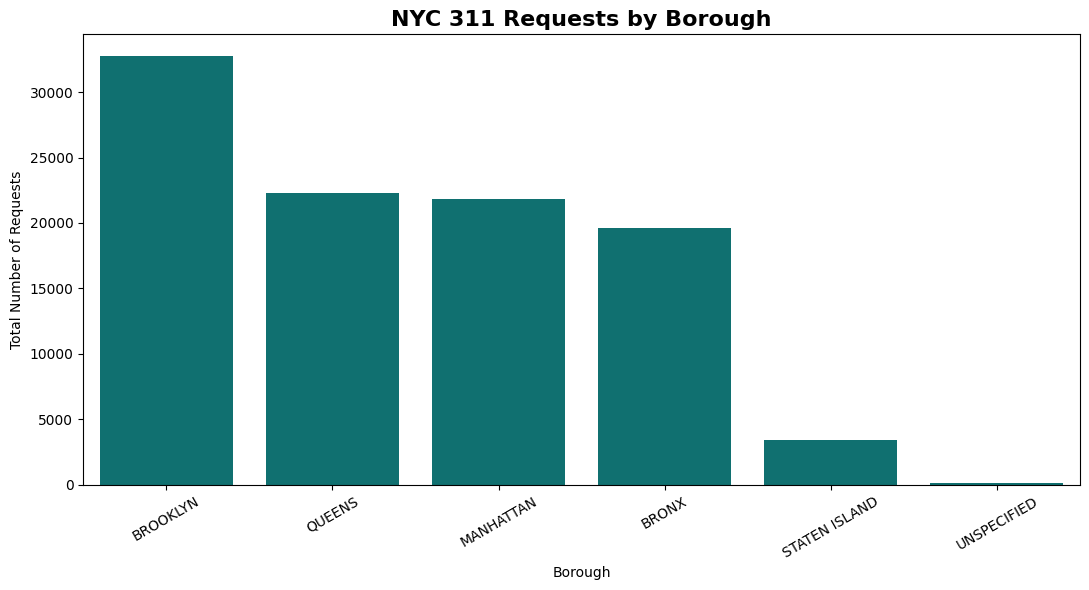

In [66]:
# Keep missing boroughs visible under a label
borough_data = df["borough"].fillna("MISSING")

borough_data = borough_data.replace({
    "Unspecified": "UNSPECIFIED"
})

borough_counts = borough_data.value_counts()

plt.figure(figsize=(11, 6))

sns.barplot(
    x=borough_counts.index,
    y=borough_counts.values,
    color="teal"
)

plt.title(
    "NYC 311 Requests by Borough",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Borough")
plt.ylabel("Total Number of Requests")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [67]:
borough_percent = (
    borough_counts / len(df) * 100
).round(2)

borough_summary = pd.DataFrame({
    "Total Requests": borough_counts,
    "Percentage": borough_percent
})

display(borough_summary)


,Total Requests,Percentage
borough,,
BROOKLYN,32779,32.78
QUEENS,22303,22.30
MANHATTAN,21831,21.83
BRONX,19597,19.60
STATEN ISLAND,3382,3.38
UNSPECIFIED,108,0.11


### Investigation 2 — Borough-Wise Complaint Distribution

**Objective:** Compare NYC 311 request volumes across boroughs.

**Method:** Used Pandas `value_counts()` to calculate borough-level request frequencies and visualized the distribution with a bar chart.

**Finding:** [Borough name] recorded the highest number of requests, with [number] complaints, accounting for [percentage]% of the dataset.

**Interpretation:** The distribution shows differences in recorded 311 request volumes across boroughs. These differences may reflect population, reporting activity, types of service needs, or dataset coverage. Additional context is needed before drawing conclusions about service quality.

In [68]:
import os

# Create a folder for EDA outputs
os.makedirs("/content/drive/MyDrive/1.Learning & Training/guvi/Mini_Project/eda_outputs", exist_ok=True)

# Save top 10 complaint data
top10_table.to_csv(
    "/content/drive/MyDrive/1.Learning & Training/guvi/Mini_Project/eda_outputs/top10_complaints.csv",
    index=False
)

# Save borough summary
borough_summary.to_csv(
    "/content/drive/MyDrive/1.Learning & Training/guvi/Mini_Project/eda_outputs/borough_summary.csv"
)

print("EDA result tables saved successfully!")


EDA result tables saved successfully!


In [69]:

# Count complaints assigned to each agency
agency_counts = df["agency"].value_counts()

# Display top 10 agencies
top10_agencies = agency_counts.head(10)

# Convert into a DataFrame
agency_table = top10_agencies.reset_index()
agency_table.columns = ["Agency", "Total Requests"]

display(agency_table)


,Agency,Total Requests
0,NYPD,41731
1,HPD,27979
2,DSNY,7237
3,DOT,6240
4,DEP,4874
5,DOB,2767
6,DPR,2747
7,DOHMH,2314
8,DHS,2219
9,TLC,982


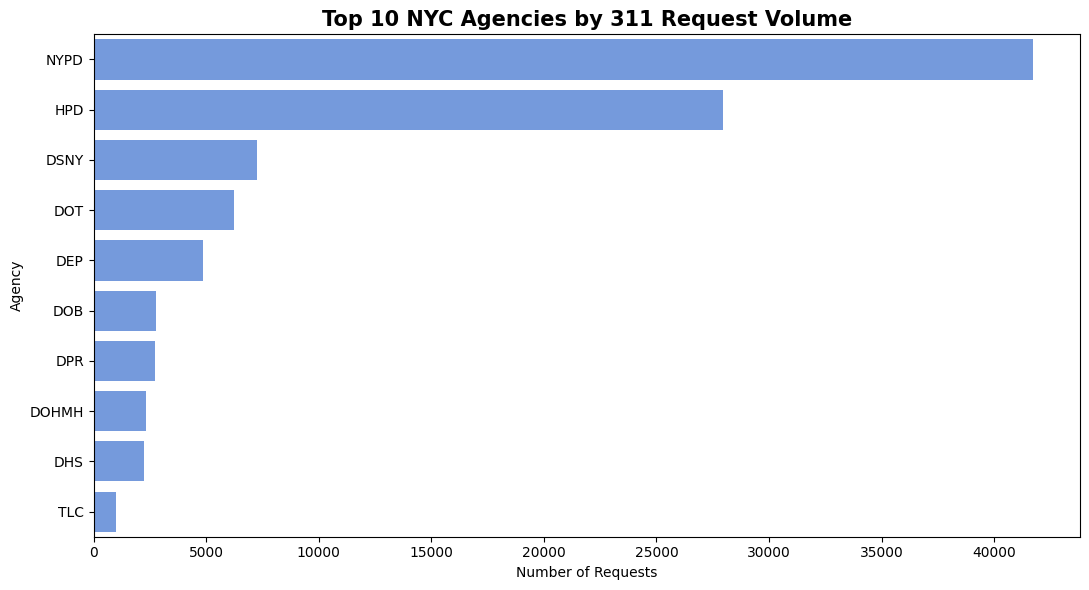

In [70]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top10_agencies.values,
    y=top10_agencies.index,
    color="cornflowerblue"
)

plt.title(
    "Top 10 NYC Agencies by 311 Request Volume",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Requests")
plt.ylabel("Agency")

plt.tight_layout()
plt.show()


In [71]:
agency_summary = agency_table.copy()

agency_summary["Percentage"] = (
    agency_summary["Total Requests"] / len(df) * 100
).round(2)

display(agency_summary)

print(
    "Agency with highest recorded workload:",
    agency_summary.iloc[0]["Agency"]
)

,Agency,Total Requests,Percentage
0,NYPD,41731,41.73
1,HPD,27979,27.98
2,DSNY,7237,7.24
3,DOT,6240,6.24
4,DEP,4874,4.87
5,DOB,2767,2.77
6,DPR,2747,2.75
7,DOHMH,2314,2.31
8,DHS,2219,2.22
9,TLC,982,0.98


Agency with highest recorded workload: NYPD


### Investigation 3 — Agency Workload Distribution

**Objective:** Identify agencies receiving the highest number of NYC 311 service requests.

**Method:** Used Pandas `value_counts()` to calculate the number of requests recorded for each agency, then visualized the top 10 using a horizontal bar chart.

**Finding:** [Agency name] received the highest recorded volume, with [number] requests, representing [percentage]% of the analyzed dataset.

**Interpretation:** Request volumes vary across agencies, suggesting differences in recorded service demand. Additional analysis of case types, agency responsibilities, and resolution durations would be needed to evaluate operational performance.

,month,total_requests
0,2026-01-01,348511
1,2026-02-01,334691
2,2026-03-01,342390
3,2026-04-01,302190
4,2026-05-01,331980
5,2026-06-01,334834
6,2026-07-01,343133
7,2026-08-01,328921
8,2026-09-01,323630


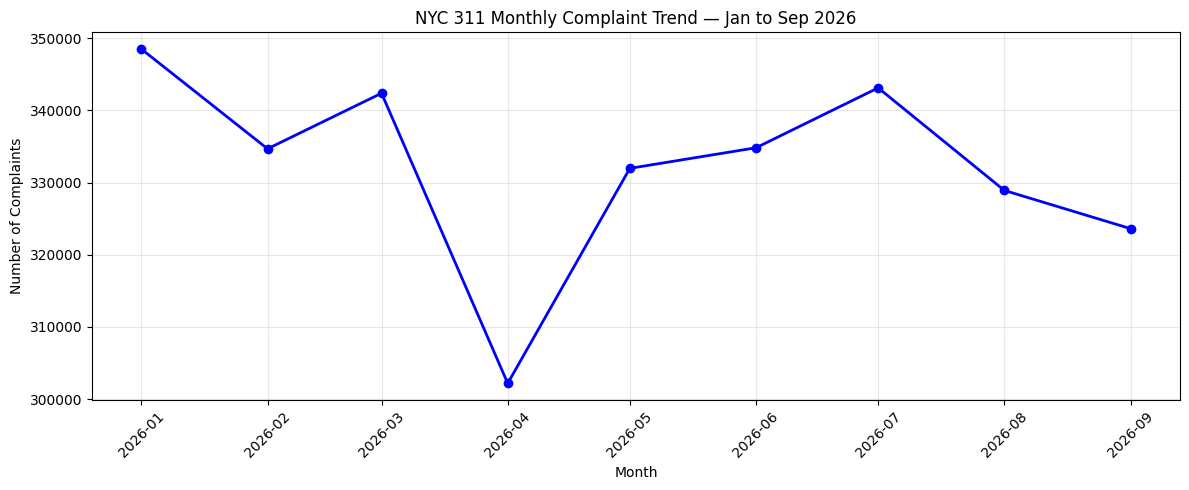

In [80]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

params = {
    "$select": (
        "date_trunc_ym(created_date) as month, "
        "count(*) as total_requests"
    ),
    "$where": (
        "created_date >= '2026-01-01T00:00:00' "
        "AND created_date < '2026-10-01T00:00:00'"
    ),
    "$group": "date_trunc_ym(created_date)",
    "$order": "month ASC",
    "$limit": 100
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

monthly_data = pd.DataFrame(response.json())

monthly_data["month"] = pd.to_datetime(
    monthly_data["month"]
)

monthly_data["total_requests"] = pd.to_numeric(
    monthly_data["total_requests"]
)

display(monthly_data)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data["month"],
    monthly_data["total_requests"],
    marker="o",
    color="blue",
    linewidth=2
)

plt.title("NYC 311 Monthly Complaint Trend — Jan to Sep 2026")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [81]:
# Find highest and lowest complaint months
highest_month = monthly_data.loc[
    monthly_data["total_requests"].idxmax()
]

lowest_month = monthly_data.loc[
    monthly_data["total_requests"].idxmin()
]

print("Highest complaint month:")
print(highest_month["month"].strftime("%B %Y"))
print("Complaints:", highest_month["total_requests"])

print("\nLowest complaint month:")
print(lowest_month["month"].strftime("%B %Y"))
print("Complaints:", lowest_month["total_requests"])

difference = (
    highest_month["total_requests"]
    - lowest_month["total_requests"]
)

print("\nDifference:", difference)

print(
    "\nTotal complaints across 9 months:",
    monthly_data["total_requests"].sum()
)


Highest complaint month:
January 2026
Complaints: 348511

Lowest complaint month:
April 2026
Complaints: 302190

Difference: 46321

Total complaints across 9 months: 2990280


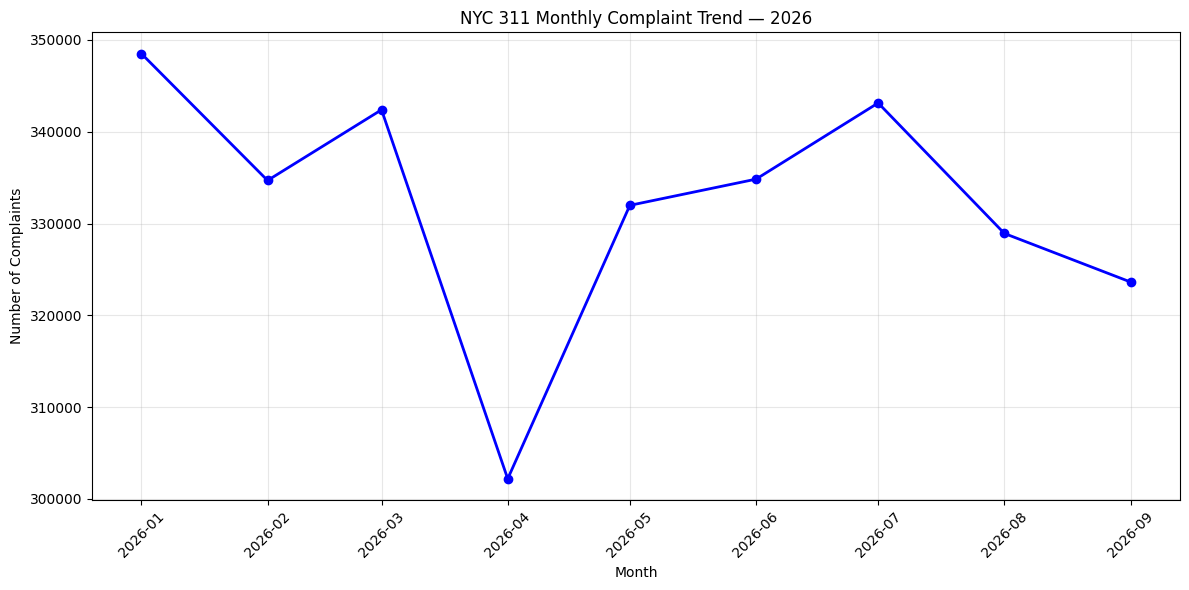

In [79]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_data["month"],
    monthly_data["total_requests"],
    marker="o",
    linewidth=2,
    color="blue"
)

plt.title("NYC 311 Monthly Complaint Trend — 2026")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "/content/monthly_complaint_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Investigation 4: Monthly Complaint Trend Analysis

**Objective:** Analyze monthly variations in NYC 311 service request volumes from January to September 2026.

**Methodology:** Retrieved aggregated monthly service request counts from the NYC Open Data API using Python. The results were visualized using a line chart created with Matplotlib.

**Key Findings:**

- January 2026 recorded the highest complaint volume, approximately 348,500 requests.
- April 2026 had the lowest volume, approximately 302,200 requests.
- A significant decline was observed between March and April.
- Complaint volume increased between April and July.
- A declining trend was observed during August and September.

**Business Interpretation:**

The analysis reveals month-to-month fluctuations in NYC 311 service request volumes. These variations can help civic administrators identify periods of relatively higher reported service demand and investigate potential operational planning needs.

**Conclusion:**

Monthly trend analysis provides insights into changes in recorded citizen service requests. Further investigation across multiple years and complaint categories is required to identify recurring seasonal patterns or explain the observed fluctuations.

**Data Scope:** January–September 2026, based on aggregated NYC Open Data API results, separate from the project's 100,000-record cleaned sample.

In [98]:

# Create weekday column
df["weekday"] = df["created_date"].dt.day_name()

# Correct weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Count requests by weekday
weekday_counts = (
    df["weekday"]
    .value_counts()
    .reindex(weekday_order, fill_value=0)
)

display(weekday_counts)


,count
weekday,
Monday,13012
Tuesday,12200
Wednesday,19457
Thursday,22084
Friday,10989
Saturday,10778
Sunday,11480


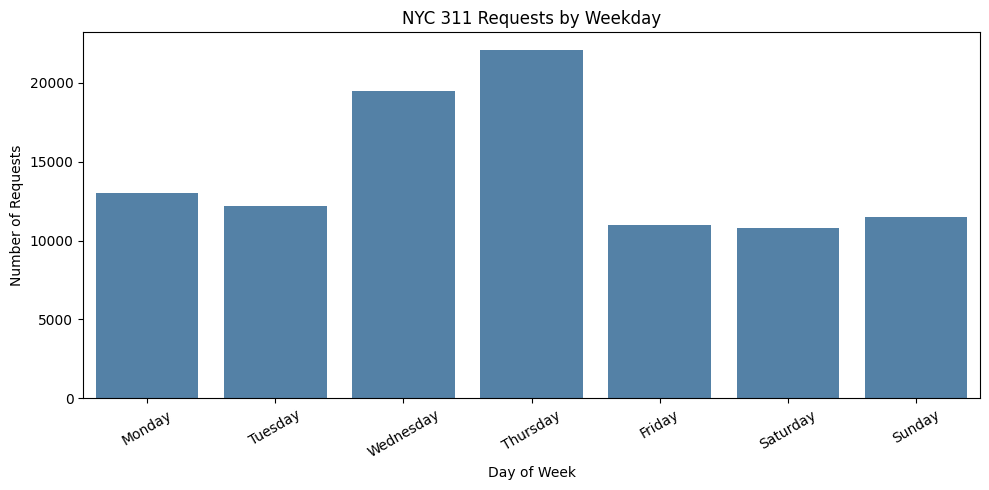

In [99]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_counts.index,
    y=weekday_counts.values,
    color="steelblue"
)

plt.title("NYC 311 Requests by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of Requests")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [100]:
print("Busiest weekday:", weekday_counts.idxmax())
print("Number of requests:", weekday_counts.max())

Busiest weekday: Thursday
Number of requests: 22084


In [101]:

# Extract hour (0–23)
df["hour"] = df["created_date"].dt.hour

# Count by hour
hourly_counts = (
    df["hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
)

display(hourly_counts)


,count
hour,
0,2955
1,2262
2,1358
3,1124
4,1171
5,1350
6,2159
7,3937
8,5236


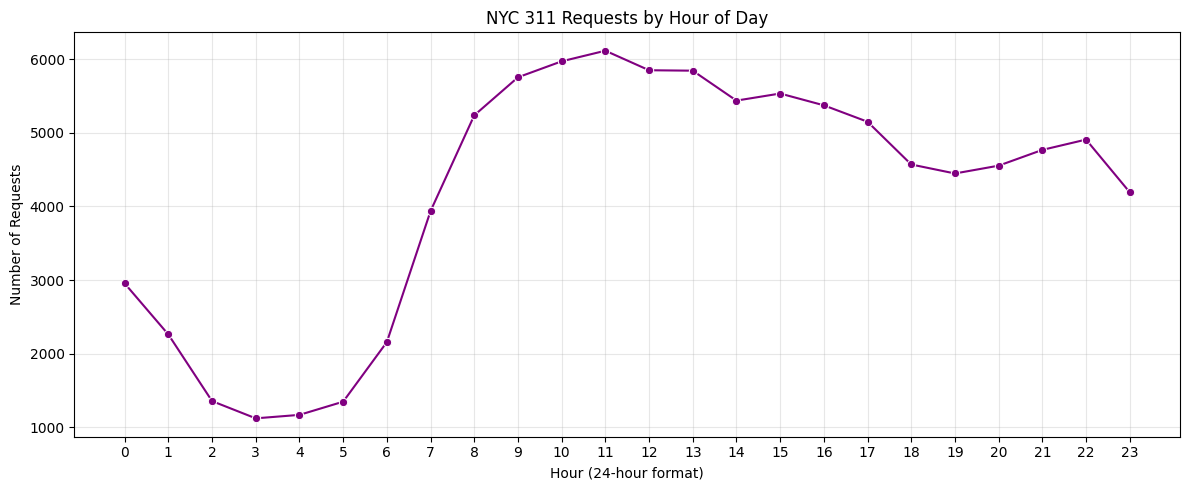

In [102]:

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_counts.index,
    y=hourly_counts.values,
    marker="o",
    color="purple"
)

plt.title("NYC 311 Requests by Hour of Day")
plt.xlabel("Hour (24-hour format)")
plt.ylabel("Number of Requests")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [103]:
print("Busiest hour:", hourly_counts.idxmax())
print("Number of requests:", hourly_counts.max())

Busiest hour: 11
Number of requests: 6113


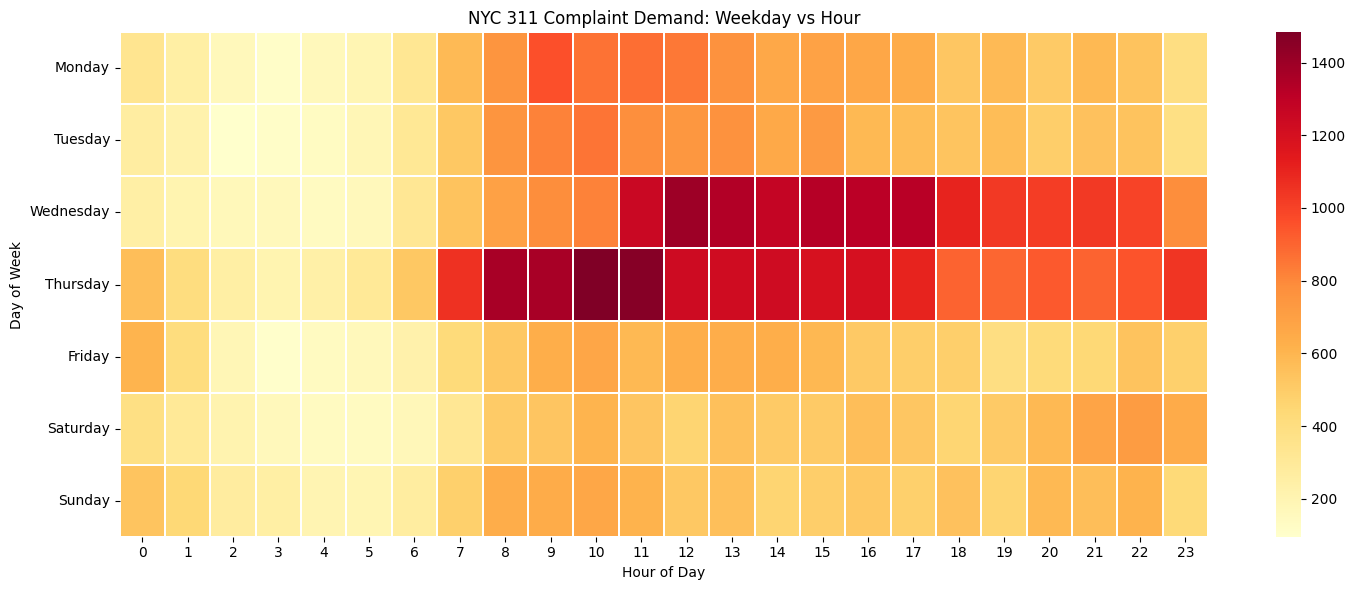

In [104]:

# Count complaints by weekday and hour
heatmap_data = pd.crosstab(
    df["weekday"],
    df["hour"]
)

# Ensure complete weekday/hour layout
heatmap_data = heatmap_data.reindex(
    index=weekday_order,
    columns=range(24),
    fill_value=0
)

plt.figure(figsize=(15, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3
)

plt.title("NYC 311 Complaint Demand: Weekday vs Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


In [105]:
busiest_day, busiest_hour = (
    heatmap_data.stack().idxmax()
)

print("Busiest day:", busiest_day)
print("Busiest hour:", busiest_hour)
print(
    "Requests:",
    heatmap_data.loc[busiest_day, busiest_hour]
)

Busiest day: Thursday
Busiest hour: 10
Requests: 1483


In [106]:

from pathlib import Path

output = Path("/content/eda_outputs")
output.mkdir(exist_ok=True)

weekday_counts.to_csv(
    output / "weekday_counts.csv"
)

hourly_counts.to_csv(
    output / "hourly_counts.csv"
)

heatmap_data.to_csv(
    output / "weekday_hour_heatmap.csv"
)

print("Investigation 5 results saved!")


Investigation 5 results saved!


### Investigation 5 — Weekday and Hourly Complaint Demand

**Objective:** Identify patterns in NYC 311 service requests across weekdays and hours of the day.

**Method:** Extracted weekday and hour from the complaint creation timestamps using Pandas. Calculated request frequencies and visualized the distributions using bar charts, a line chart, and a heatmap.

**Key Findings:**

- The weekday with the highest request volume was [weekday], with [number] requests.
- The busiest hour was [hour], with [number] requests.
- The highest weekday-hour combination was [weekday and hour], with [number] requests.

**Business Interpretation:**

The observed patterns indicate when higher volumes of service requests were recorded within the analyzed dataset. These patterns may help inform further investigation of service-demand periods.

**Limitation:** This analysis uses the project's approximately 100,000-record October 2026 sample. Its time coverage may be incomplete, and recorded creation times may not always correspond to the time a citizen first experienced a problem.